# 03 - Exploratory data analysis

Exploratory analysis of the delivery delay of Olist orders, built on the two tables exported by `02_data_preparation.ipynb` (`data/processed/orders.csv` and `order_items.csv`, D15). This notebook does not connect to the database.

Contents:

1. Load the processed files with explicit types and check the control totals (D2, D9, D15).
2. Promised versus actual delivery time by region and state: test of the North promise hypothesis with the criteria fixed in D16 before this notebook was written.
3. Distributions (descriptive box plots, extremes kept, D13).
4. Statistical test: review score of late versus not-late orders.
5. Summary of findings.

Decision numbers (D1 to D16) refer to `docs/decisions.md`.

In [1]:
from pathlib import Path

import matplotlib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import scipy
from scipy import stats

DATA_DIR = Path("..") / "data" / "processed"
ORDERS_PATH = DATA_DIR / "orders.csv"
ITEMS_PATH = DATA_DIR / "order_items.csv"

for path in [ORDERS_PATH, ITEMS_PATH]:
    assert path.exists(), f"Missing file: {path}"
    print(f"{path.name}: {path.stat().st_size / 1e6:.1f} MB")

print(
    f"pandas {pd.__version__} | numpy {np.__version__} | scipy {scipy.__version__} | "
    f"matplotlib {matplotlib.__version__}"
)

orders.csv: 25.5 MB
order_items.csv: 25.2 MB
pandas 3.1.1 | numpy 2.5.5 | scipy 1.18.1 | matplotlib 3.11.2


## 1. Load and check

Both files are read with explicit column types, as Power Query does (D15): IDs and ZIP prefixes as text, flags as nullable booleans, whole days and scores as nullable integers. The control totals are then checked against `docs/decisions.md` before any analysis. Expected values come from the decisions log (verified by SQL in notebook 02), never from this notebook.

In [2]:
ORDERS_DTYPES = {
    "order_id": "string", "customer_unique_id": "string", "customer_zip_code_prefix": "string",
    "customer_city": "string", "customer_state": "string", "order_status": "string",
    "in_delay_scope": "boolean", "is_late": "boolean", "has_distance": "boolean",
    "flag_approval_before_purchase": "boolean", "flag_carrier_before_approval": "boolean",
    "flag_carrier_before_purchase": "boolean", "flag_delivery_before_carrier": "boolean",
    "delivery_delay_days": "Int64", "promised_delivery_days": "Int64",
    "actual_delivery_days": "Int64", "review_score": "Int64", "distance_km": "Float64",
}
ORDERS_DATES = ["purchase_ts", "approved_ts", "carrier_ts", "delivered_ts", "estimated_date", "purchase_month"]

ITEMS_DTYPES = {
    "order_id": "string", "product_id": "string", "seller_id": "string",
    "seller_zip_code_prefix": "string", "seller_city": "string", "seller_state": "string",
    "category": "string", "category_source": "string", "customer_state": "string",
    "order_item_id": "Int64", "in_delay_scope": "boolean", "is_late": "boolean",
    "delivery_delay_days": "Int64", "price": "Float64", "freight_value": "Float64",
    "product_weight_g": "Float64", "product_length_cm": "Float64",
    "product_height_cm": "Float64", "product_width_cm": "Float64", "distance_km": "Float64",
}
ITEMS_DATES = ["shipping_limit_ts"]

orders = pd.read_csv(ORDERS_PATH, encoding="utf-8-sig", dtype=ORDERS_DTYPES, parse_dates=ORDERS_DATES)
items = pd.read_csv(ITEMS_PATH, encoding="utf-8-sig", dtype=ITEMS_DTYPES, parse_dates=ITEMS_DATES)

print(f"orders: {orders.shape} | items: {items.shape}")

typed_orders = set(ORDERS_DTYPES) | set(ORDERS_DATES)
typed_items = set(ITEMS_DTYPES) | set(ITEMS_DATES)
print(f"orders columns without an explicit type: {[c for c in orders.columns if c not in typed_orders]}")
print(f"items columns without an explicit type: {[c for c in items.columns if c not in typed_items]}")
print(orders[ORDERS_DATES].dtypes.to_string())

orders: (99441, 24) | items: (112650, 21)
orders columns without an explicit type: []
items columns without an explicit type: []
purchase_ts       datetime64[us]
approved_ts       datetime64[us]
carrier_ts        datetime64[us]
delivered_ts      datetime64[us]
estimated_date    datetime64[us]
purchase_month    datetime64[us]


In [3]:
scope = orders["in_delay_scope"]
late = scope & orders["is_late"].fillna(False)
reviewed = orders["review_score"].notna()

EXPECTED = {
    "orders": 99441, "item_rows": 112650, "delivered": 96478, "delay_scope": 96470,
    "late": 6534, "delivered_on_estimated_date": 1292, "items_in_scope": 110189,
    "reviewed_in_scope": 95824, "reviewed_late": 6381, "missing_distance_in_scope": 481,
}
observed = {
    "orders": len(orders),
    "item_rows": len(items),
    "delivered": (orders["order_status"] == "delivered").sum(),
    "delay_scope": scope.sum(),
    "late": late.sum(),
    "delivered_on_estimated_date": (scope & (orders["delivery_delay_days"] == 0).fillna(False)).sum(),
    "items_in_scope": items["in_delay_scope"].fillna(False).sum(),
    "reviewed_in_scope": (scope & reviewed).sum(),
    "reviewed_late": (late & reviewed).sum(),
    "missing_distance_in_scope": (scope & ~orders["has_distance"]).sum(),
}
checks = pd.DataFrame({"expected": EXPECTED, "observed": {k: int(v) for k, v in observed.items()}})
checks["status"] = (checks["expected"] == checks["observed"]).map({True: "PASS", False: "FAIL"})
print(checks.to_string())

late_rate = round(late.sum() / scope.sum() * 100, 2)
avg_days_late = round(float(orders.loc[late, "delivery_delay_days"].mean()), 2)
keys_unique = orders["order_id"].is_unique and not items.duplicated(["order_id", "order_item_id"]).any()
identity_ok = bool((
    orders.loc[scope, "actual_delivery_days"] - orders.loc[scope, "promised_delivery_days"]
    == orders.loc[scope, "delivery_delay_days"]
).all())
scope_has_times = bool(orders.loc[scope, ["promised_delivery_days", "actual_delivery_days"]].notna().all().all())

print(f"\nLate rate: {late_rate}% (expected 6.77)")
print(f"Average days late, per order: {avg_days_late} (expected 10.62)")
print(f"Grain keys unique: {keys_unique}")
print(f"D13 identity in scope: {identity_ok}")
print(f"Promised and actual times present for every order in scope: {scope_has_times}")

assert (checks["status"] == "PASS").all()
assert late_rate == 6.77 and avg_days_late == 10.62
assert keys_unique and identity_ok and scope_has_times

                             expected  observed status
orders                          99441     99441   PASS
item_rows                      112650    112650   PASS
delivered                       96478     96478   PASS
delay_scope                     96470     96470   PASS
late                             6534      6534   PASS
delivered_on_estimated_date      1292      1292   PASS
items_in_scope                 110189    110189   PASS
reviewed_in_scope               95824     95824   PASS
reviewed_late                    6381      6381   PASS
missing_distance_in_scope         481       481   PASS

Late rate: 6.77% (expected 6.77)
Average days late, per order: 10.62 (expected 10.62)
Grain keys unique: True
D13 identity in scope: True
Promised and actual times present for every order in scope: True


## 2. North promise hypothesis (D16)

Stage 1 showed North states combining a high freight share with a low late rate (RO 2.9%, AM 2.8%), the opposite of the Northeast. Hypothesis (not-investigated item 8): the North is rarely late because it receives a more generous delivery promise, not because delivery is fast.

Slack = promised days - actual days, which equals minus the delay (D13). Slack alone therefore restates the late rate, so the test separates the promise from the delivery speed. Criteria fixed in D16 before this section was written (population: 96,470 orders in scope; medians decide, means shown; baseline: whole country, North included):

- C1 (delivery is not faster): North median actual days >= national median actual days.
- C2 (more generous promise): North median slack >= national median slack + `X_DAYS` (`X_DAYS = 5`).
- C3 (consistency): in more than half of the North states with at least 100 orders in scope, the median slack is above the national median slack.

Verdict: supported (C1, C2, C3); partially supported (C2 and C3 without C1); not supported (any other combination). The North-minus-national slack difference is reported whatever the verdict. The result is exploratory: the hypothesis came from this same dataset (D16).

In [4]:
X_DAYS = 5
MIN_STATE_ORDERS = 100

REGION_BY_STATE = {
    **dict.fromkeys(["AC", "AM", "AP", "PA", "RO", "RR", "TO"], "North"),
    **dict.fromkeys(["AL", "BA", "CE", "MA", "PB", "PE", "PI", "RN", "SE"], "Northeast"),
    **dict.fromkeys(["DF", "GO", "MS", "MT"], "Center-West"),
    **dict.fromkeys(["ES", "MG", "RJ", "SP"], "Southeast"),
    **dict.fromkeys(["PR", "RS", "SC"], "South"),
}
REGION_ORDER = ["North", "Northeast", "Center-West", "Southeast", "South", "Brazil"]

scoped = orders.loc[scope, ["order_id", "customer_state", "is_late",
                            "promised_delivery_days", "actual_delivery_days"]].copy()
scoped["slack_days"] = scoped["promised_delivery_days"] - scoped["actual_delivery_days"]
scoped["region"] = scoped["customer_state"].map(REGION_BY_STATE)

print(f"Orders in scope: {len(scoped)} | states: {scoped['customer_state'].nunique()} | "
      f"unmapped states: {scoped['region'].isna().sum()}")
assert len(scoped) == 96470 and len(REGION_BY_STATE) == 27 and scoped["region"].notna().all()


def delivery_summary(df, by):
    """Orders, late rate and promised/actual/slack days (median and mean) per group."""
    table = df.groupby(by).agg(
        orders=("order_id", "size"),
        late_rate_pct=("is_late", "mean"),
        promised_median=("promised_delivery_days", "median"),
        promised_mean=("promised_delivery_days", "mean"),
        actual_median=("actual_delivery_days", "median"),
        actual_mean=("actual_delivery_days", "mean"),
        slack_median=("slack_days", "median"),
        slack_mean=("slack_days", "mean"),
    )
    table.insert(1, "share_pct", table["orders"] / len(df) * 100)
    table["late_rate_pct"] = table["late_rate_pct"] * 100
    return table.round(2)


region_table = pd.concat([
    delivery_summary(scoped, "region"),
    delivery_summary(scoped.assign(region="Brazil"), "region"),
]).reindex(REGION_ORDER)
print(region_table.to_string())

Orders in scope: 96470 | states: 27 | unmapped states: 0
             orders  share_pct  late_rate_pct  promised_median  promised_mean  actual_median  actual_mean  slack_median  slack_mean
region                                                                                                                             
North          1796       1.86           8.57             37.0          38.15           20.0        22.54          17.0       15.61
Northeast      9044       9.37          12.72             31.0          31.29           17.0        19.95          13.0       11.34
Center-West    5624       5.83           6.53             27.0          27.29           13.0        14.95          13.0       12.34
Southeast     66193      68.62           6.12             22.0          22.25            9.0        10.69          12.0       11.56
South         13813      14.32            5.9             26.0          27.06           12.0        13.98          14.0       13.08
Brazil        96470

### 2.1 States and verdict

All 27 states are shown; states below `MIN_STATE_ORDERS` stay in the regional and national figures but are not reported individually as findings (D16). The verdict applies the three conditions exactly as fixed in D16.

In [5]:
state_table = delivery_summary(scoped, "customer_state")
state_table.insert(0, "region", state_table.index.map(REGION_BY_STATE))
state_table["meets_min_orders"] = state_table["orders"] >= MIN_STATE_ORDERS
state_table = state_table.sort_values(["region", "orders"], ascending=[True, False])
print(state_table.to_string())

national = region_table.loc["Brazil"]
north = region_table.loc["North"]
north_states = state_table[(state_table["region"] == "North") & state_table["meets_min_orders"]]

c1 = north["actual_median"] >= national["actual_median"]
c2 = north["slack_median"] >= national["slack_median"] + X_DAYS
c3_count = int((north_states["slack_median"] > national["slack_median"]).sum())
c3 = c3_count > len(north_states) / 2

if c1 and c2 and c3:
    verdict = "supported"
elif c2 and c3:
    verdict = "partially supported"
else:
    verdict = "not supported"

print(f"\nNorth states with >= {MIN_STATE_ORDERS} orders: {list(north_states.index)}")
print(f"C1 actual median: North {north['actual_median']} vs Brazil {national['actual_median']} -> {c1}")
print(f"C2 slack median: North {north['slack_median']} vs Brazil {national['slack_median']} + {X_DAYS} -> {c2}")
print(f"C3 North states with slack median above Brazil: {c3_count} of {len(north_states)} -> {c3}")
# Mean difference from unrounded values (region_table is rounded to 2 decimals)
slack_mean_diff = (scoped.loc[scoped["region"] == "North", "slack_days"].mean()
                   - scoped["slack_days"].mean())
print(f"North minus Brazil slack: median {north['slack_median'] - national['slack_median']:.1f} days, "
      f"mean {slack_mean_diff:.2f} days")
print(f"Verdict (X_DAYS = {X_DAYS}): {verdict}")

                     region  orders  share_pct  late_rate_pct  promised_median  promised_mean  actual_median  actual_mean  slack_median  slack_mean  meets_min_orders
customer_state                                                                                                                                                       
DF              Center-West    2080       2.16           5.67             25.0          24.95           11.0         12.9          13.0       12.05              True
GO              Center-West    1957       2.03           6.54             27.0          27.72           14.0        15.54          13.0       12.19              True
MT              Center-West     886       0.92           5.98             32.0          32.37           16.0         18.0          15.0       14.36              True
MS              Center-West     701       0.73            9.7             26.0           26.6           14.0        15.54          12.0       11.05              True
PA  

**Result (D16, `X_DAYS = 5`): supported.**

- C1: North median actual time is 20 days against 10 nationally.
- C2: North median slack is 17 days against 12 + 5. The condition is met exactly at the boundary in whole days, and the difference in means is only 3.74 days, so C2 is fragile.
- C3: all 4 North states with at least 100 orders (PA, TO, RO, AM) have a median slack above 12 days (TO by only 1 day).

The premise of item 8 does not hold at region level: the North late rate is 8.57%, above the national 6.77%. The low rates come from RO (2.88%) and AM (2.76%), while PA (11.21%) and TO (9.85%), together 67.9% of North orders in scope, are late more often than the country. The North has the largest median slack of the five regions and is still late more often than average.

Median slack does not rank late rates across regions or states (Northeast: slack 13 days, late 12.72%; Southeast: slack 12 days, late 6.12%). The clearest case is SP: one of the smallest median slacks among states with at least 100 orders (11 days; only AL is lower) and one of the lowest late rates (4.49%), because its actual times are short (median 7 days). An order is late when its slack is negative, so the late rate depends on the lower tail of the slack distribution, not on its median; section 3 shows the distributions.

The result is exploratory (the hypothesis came from this dataset, D16) and describes an association, not a cause.

## 3. Distributions

Box plots are descriptive: no value is removed (D13). Boxes span the interquartile range, the thick line is the median, whiskers reach 1.5 times the interquartile range, and points beyond them are drawn individually. An order is late when its slack is below 0. The number of points beyond the whiskers reflects volume (the Southeast has 66,193 orders), so the late rate printed under each box is the comparable measure.

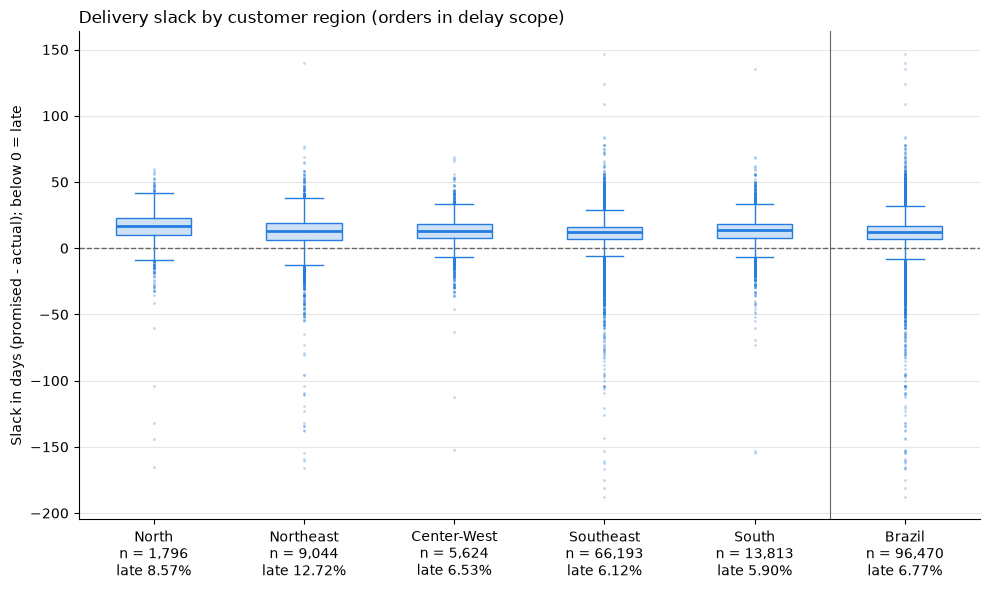

In [6]:
BOX_EDGE = "#257de0"
BOX_FILL = "#cfe1f7"
TEXT_SECONDARY = "#666666"

plot_data = pd.concat([scoped, scoped.assign(region="Brazil")])
groups = [plot_data.loc[plot_data["region"] == r, "slack_days"].to_numpy(dtype=float) for r in REGION_ORDER]
labels = [
    f"{r}\nn = {region_table.loc[r, 'orders']:,}\nlate {region_table.loc[r, 'late_rate_pct']:.2f}%"
    for r in REGION_ORDER
]

fig, ax = plt.subplots(figsize=(10, 6))
ax.boxplot(
    groups, tick_labels=labels, widths=0.5, patch_artist=True,
    boxprops={"facecolor": BOX_FILL, "edgecolor": BOX_EDGE},
    medianprops={"color": BOX_EDGE, "linewidth": 2},
    whiskerprops={"color": BOX_EDGE}, capprops={"color": BOX_EDGE},
    flierprops={"marker": "o", "markersize": 2, "markerfacecolor": BOX_EDGE,
                "markeredgecolor": "none", "alpha": 0.3},
)
ax.axhline(0, color=TEXT_SECONDARY, linewidth=1, linestyle="--")
ax.axvline(len(REGION_ORDER) - 0.5, color=TEXT_SECONDARY, linewidth=0.8)
ax.set_ylabel("Slack in days (promised - actual); below 0 = late")
ax.set_title("Delivery slack by customer region (orders in delay scope)", loc="left")
ax.grid(axis="y", color="#e6e6e6", linewidth=0.8)
ax.set_axisbelow(True)
ax.spines[["top", "right"]].set_visible(False)
fig.tight_layout()
plt.show()

Median slack lies between 12 and 17 days in every region, and every box sits above 0. What separates the regions is how far the lower part of each distribution reaches below 0: the Northeast's lower whisker goes furthest down and it has the highest late rate (12.72%), while the South (5.90%) and the Southeast (6.12%) stay closer to 0. This is consistent with section 2: the late rate is set by the lower tail of the slack distribution, which the median does not describe.

## 4. Statistical test: review score of late versus not-late orders

Declared before running:

- Population: orders in the delay scope with a review (D5): 6,381 late and 89,443 not late.
- H0: the distribution of `review_score` is the same in both groups. Test: two-sided Mann-Whitney U (`scipy.stats.mannwhitneyu`), because the score is ordinal (1 to 5) with many ties.
- Why this test (rationale expanded after the run; the choice itself was declared before): the score is ordinal, so differences between levels are not known to be equal. A t-test compares means and assumes equal distances between scores; a chi-square test on the 2 x 5 table ignores the order of the scores; an ordinal logistic regression could control for state or category but belongs to the modeling project. Mann-Whitney uses only the order of the scores, needs no normality assumption, handles ties with a correction, and its effect size has a plain reading (the probability that one group scores higher).
- Group order: late first, so U is the statistic of the late group.
- Effect size: rank-biserial correlation r = 1 - 2U / (n1 * n2), where U / (n1 * n2) is the probability that a random late order has a higher score than a random not-late order (ties count half). r > 0 means late orders tend to score lower. Reading of |r|: below 0.1 negligible, 0.1 to 0.3 small, 0.3 to 0.5 medium, 0.5 or more large.
- Complementary measure: difference in the share of scores 1-2 (late minus not late), with a 95% Wald confidence interval.
- With about 95,000 orders the p-value will be tiny for almost any difference, so the conclusion rests on the effect size, not on the p-value.
- Interpretation limits: association, not cause. Part of the effect is mechanical: for 74.5% of the reviewed late orders the survey was created before delivery (D5), so those scores rate a missed promise rather than the delivered product.

In [7]:
reviewed = orders["review_score"].notna()
late_scores = orders.loc[late & reviewed, "review_score"].to_numpy(dtype=float)
not_late_scores = orders.loc[scope & ~late & reviewed, "review_score"].to_numpy(dtype=float)
n_late, n_not_late = len(late_scores), len(not_late_scores)
print(f"Reviewed orders in scope: late {n_late:,} | not late {n_not_late:,}")
assert (n_late, n_not_late) == (6381, 89443)

mw = stats.mannwhitneyu(late_scores, not_late_scores, alternative="two-sided")
u_late = mw.statistic
prob_late_higher = u_late / (n_late * n_not_late)
rank_biserial = 1 - 2 * prob_late_higher

low_late = (late_scores <= 2).mean()
low_not_late = (not_late_scores <= 2).mean()
diff = low_late - low_not_late
se = np.sqrt(low_late * (1 - low_late) / n_late + low_not_late * (1 - low_not_late) / n_not_late)
z = stats.norm.ppf(0.975)
ci_low, ci_high = diff - z * se, diff + z * se

print(f"\nMann-Whitney U (late group): {u_late:,.0f} | p-value: {mw.pvalue:.3g}")
print(f"P(late score > not-late score), ties count half: {prob_late_higher:.3f}")
print(f"Rank-biserial correlation r = 1 - 2U/(n1*n2): {rank_biserial:.3f}")
print(f"\nShare of scores 1-2: late {low_late:.2%} | not late {low_not_late:.2%}")
print(f"Difference: {diff * 100:.2f} percentage points (95% CI {ci_low * 100:.2f} to {ci_high * 100:.2f})")

Reviewed orders in scope: late 6,381 | not late 89,443

Mann-Whitney U (late group): 103,305,546 | p-value: 0
P(late score > not-late score), ties count half: 0.181
Rank-biserial correlation r = 1 - 2U/(n1*n2): 0.638

Share of scores 1-2: late 62.42% | not late 9.27%
Difference: 53.15 percentage points (95% CI 51.95 to 54.36)


**Result.** The rank-biserial correlation is r = 0.638, a large effect on the scale declared above: in a random pair, the late order has the higher score in only 18.1% of cases (ties count half). The share of scores 1-2 is 62.42% for late orders against 9.27% for not-late orders, a difference of 53.15 percentage points (95% CI 51.95 to 54.36). The p-value is below floating-point precision (printed as 0) and is reported as p < 0.001; it adds nothing to the effect size. This is consistent with the average scores in D5 (2.27 against 4.29).

This is an association, not a cause, and part of it is mechanical: for 74.5% of the reviewed late orders the survey was created before delivery (D5). The practical reading for the business: send the review survey after the actual delivery, or warn the customer proactively when an order is going to be late.

## 5. Summary

1. **Data checks.** The re-read files match the decisions log: 10 control counts, late rate 6.77% (D9) and average delay 10.62 days among late orders (D15).
2. **North promise hypothesis (D16): supported, exploratory.** The North has the longest actual delivery (median 20 days against 10 nationally) and the largest median slack (17 days against 12). C2 is met exactly at the boundary, and the difference in means is only 3.74 days. The premise of the hypothesis did not hold at region level: the North late rate is 8.57%, above the national 6.77%. RO (2.88%) and AM (2.76%) are rarely late, while PA (11.21%) and TO (9.85%), 67.9% of North orders, are late more often than the country.
3. **The late rate follows the lower tail, not the median slack.** SP has one of the smallest median slacks (11 days) and one of the lowest late rates (4.49%); RJ has more slack (13 days) and a late rate of 12.11%. The Northeast has the highest regional late rate (12.72%) with a median slack of 13 days.
4. **Late orders are rated much worse.** Rank-biserial r = 0.638 (large); scores 1-2 make up 62.42% of late orders against 9.27% of not-late orders (difference 53.15 percentage points, 95% CI 51.95 to 54.36). Part of the effect is mechanical: 74.5% of the reviewed late orders were surveyed before delivery (D5).

**Limitations.** The North result is exploratory (the hypothesis came from this dataset). Medians are in whole days, so differences of one day sit at the resolution limit. The national baseline is 68.6% Southeast orders. States with fewer than 100 orders in scope (AC, AP, RR) are not reported individually. Associations only, no causal claims.

**Next.** Stage 3 (Excel) and Stage 4 (Power BI) read the same two files. The comparison of promised and actual days by region belongs to the Power BI logistics page.